# 6.6 How Transformers Learn and Generate Text

**Module 6 · Note 6**

Everything is in place. In Note 6.5 we assembled a 162,561-parameter decoder-only Transformer, checked that its starting loss was sensible, that its causal mask blocked the future, and that it could learn, and we saw it write random characters. In this final note of the module, we teach it to write Shakespeare.

We will look at learning and generation as two halves of one idea. During **training**, the model is shown real text and, at every position at once, learns to predict the next character. During **generation**, it has no real text to lean on: it predicts one character, adds it to the text, and predicts again, feeding on its own output. Understanding both halves, and the difference between them, explains most of what language models can and cannot do.

Along the way, we will use the training-stability tools from Module 3 and Note 6.4 (AdamW, warmup, learning-rate schedules and gradient clipping), choose the learning rate on validation data, read the loss curves, look inside the trained model's attention, and compare the decoding strategies that decide how generated text sounds.

**Key question:** *How does a Transformer learn from text, and how does it turn what it learned into new text?*

**By the end of this note you will be able to:**
- explain next-token prediction, label shifting and the cross-entropy loss for language modelling;
- explain teacher forcing and why it makes Transformer training parallel;
- train a Transformer language model with AdamW, warmup, cosine decay and gradient clipping, choosing the learning rate on validation data;
- read loss curves against meaningful baselines;
- generate text autoregressively, and explain greedy decoding, temperature, top-k and top-p sampling;
- explain the differences between training and inference.

**Before you start:** read Notes 6.2 to 6.5. This notebook trains a model from scratch and takes about two and a half minutes to run on a CPU.

### Setup

Run this cell first. The next cell loads Tiny Shakespeare and defines the model exactly as built in Note 6.5, so this notebook is self-contained.

In [1]:
import os, re, math, copy, collections, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## 1. The Big Picture: From Training Examples to Language Generation

Here is the whole story in two loops.

**The training loop** (repeated many times):

1. Take a batch of real text windows, and their targets: the same windows shifted one character left.
2. Run the model once; it predicts the next character at every position.
3. Measure how wrong it was with cross-entropy loss.
4. Backpropagate and update the weights.

**The generation loop** (repeated once per new character):

1. Run the model on the text so far.
2. Take its probability distribution for the next character.
3. Choose one character from that distribution.
4. Append it to the text and repeat.

> 🖼 *IMAGE 6.6.1 — Learning vs. Generating.* Two horizontal panels on a white background. Top panel, titled "Training (teacher forcing, all positions at once)": a row of real character tiles "R O M E O :" feeding upward into a wide blue box "Transformer", which outputs a row of predicted tiles above every position; each prediction is compared, via a small "≠ / =" symbol, with the true next character shown in a green row ("O M E O : \n"), and all comparisons feed into one red box "loss → backpropagation". Bottom panel, titled "Generation (one character at a time)": the prompt "ROMEO:\n" feeds into the same blue box, which outputs one distribution bar chart at the last position only; an arrow labelled "sample" picks a character "T", which loops back with a curved arrow to the end of the input row; small numbers 1, 2, 3 on successive loops show "Th", "Tho"... Takeaway: training checks every position against real text in one pass; generation builds text one choice at a time from the model's own output.

The first half of this note (Sections 2–7) is about training; the second half (Sections 8–10) is about generation.

In [2]:
PATH = "data/shakespeare/input.txt"
os.makedirs("data/shakespeare", exist_ok=True)
if not os.path.exists(PATH):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", PATH)
text = open(PATH, encoding="utf-8").read()
chars = sorted(set(text)); V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(itos[i] for i in ids)
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data)); train_ids, val_ids = data[:n], data[n:]
CONTEXT, BATCH = 64, 32
def get_batch(split, generator, batch_size=BATCH):
    d = train_ids if split == "train" else val_ids
    s = torch.randint(0, len(d) - CONTEXT - 1, (batch_size,), generator=generator)
    return torch.stack([d[i:i + CONTEXT] for i in s]), torch.stack([d[i + 1:i + CONTEXT + 1] for i in s])

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model); self.proj = nn.Linear(d_model, d_model)
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)
        q, k, v = [t.view(B, T, self.n_heads, D // self.n_heads).transpose(1, 2) for t in (q, k, v)]
        return self.proj(F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D))

class Block(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads)
        self.ffn = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.ffn(self.ln2(x))

class GPT(nn.Module):
    def __init__(self, vocab_size, d_model=64, n_heads=4, n_layers=3, context=CONTEXT):
        super().__init__()
        self.context = context
        self.tok_emb, self.pos_emb = nn.Embedding(vocab_size, d_model), nn.Embedding(context, d_model)
        self.blocks = nn.ModuleList([Block(d_model, n_heads) for _ in range(n_layers)])
        self.ln_f, self.head = nn.LayerNorm(d_model), nn.Linear(d_model, vocab_size)
    def forward(self, ids, targets=None):
        x = self.tok_emb(ids) + self.pos_emb(torch.arange(ids.shape[1]))
        for b in self.blocks: x = b(x)
        logits = self.head(self.ln_f(x))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

print("training tokens:", len(train_ids), "| validation tokens:", len(val_ids), "| vocabulary:", V)
print("model parameters:", sum(p.numel() for p in GPT(V).parameters()))

training tokens: 1003854 | validation tokens: 111540 | vocabulary: 65
model parameters: 162561


The model and data are exactly as before: 1,003,854 training characters, 111,540 validation characters, a 65-character vocabulary, and a model with 162,561 parameters.

## 2. Next-Token Prediction

A language model is trained on one deceptively simple task: **given the text so far, predict the next token**. No labels are needed beyond the text itself; every character in the training data is the answer to the question "what comes after the characters before it?". This makes language modelling **self-supervised**, like the skip-gram objective in Note 5.3, and it is why language models can learn from enormous amounts of raw text.

Why should such a simple task produce anything impressive? Because predicting the next character *well* requires a lot of knowledge. To predict that "KING RICH" continues with "A", the model must have learned character names. To predict a line break followed by a speaker's name in capitals, it must have learned the layout of a play. To predict the end of a word it has never seen in exactly that context, it must have learned spelling patterns. Every regularity in the text becomes a way to reduce the loss. Large language models are trained on exactly this task, with subword tokens and vastly more text, and the knowledge they show is a by-product of predicting the next token very well.

## 3. Training Targets and Label Shifting

As we set up in Note 6.2, each training example is a window of text `x` and a target `y` that is the same window shifted one position to the left, so that `y[t]` is the character that follows `x[t]`.

In [3]:
x, y = get_batch("train", torch.Generator().manual_seed(0), batch_size=1)
print("input :", repr(decode(x[0, :24].tolist())))
print("target:", repr(decode(y[0, :24].tolist())))
print("target equals input shifted by one?", torch.equal(x[0, 1:], y[0, :-1]))

input : 't, for his purpose in th'
target: ', for his purpose in the'
target equals input shifted by one? True


The input begins `'t, for his purpose in th'` and the target begins one character later, `', for his purpose in the'`. The check confirms that the target is exactly the input shifted by one (`True`). Combined with the causal mask, this shift turns one window into many separate questions: at position t, "having seen `x[0]` to `x[t]`, what is `y[t]`?".

## 4. Cross-Entropy Loss for Language Modelling

At each position, the model outputs a probability distribution over the 65 characters. The loss at that position is **−log(the probability the model gave to the correct next character)**, and the overall loss is the average over all positions. This is the same cross-entropy loss you have used for classification since Module 1; a language model is simply a 65-way classifier applied at every position.

Here is a single position worked by hand, with three possible tokens:

In [4]:
logits = torch.tensor([2.0, 1.0, 0.1])
target = 0
probs = F.softmax(logits, dim=0)
print("probabilities:", [round(v, 3) for v in probs.tolist()])
print("loss by hand, -log p(target):", round(-math.log(probs[target].item()), 4))
print("F.cross_entropy:             ", round(F.cross_entropy(logits.unsqueeze(0), torch.tensor([target])).item(), 4))
for p in [0.9, 0.5, 0.1, 0.01]:
    print(f"probability on the correct token {p:<4} -> loss {-math.log(p):.3f}")

probabilities: [0.659, 0.242, 0.099]
loss by hand, -log p(target): 0.417
F.cross_entropy:              0.417
probability on the correct token 0.9  -> loss 0.105
probability on the correct token 0.5  -> loss 0.693
probability on the correct token 0.1  -> loss 2.303
probability on the correct token 0.01 -> loss 4.605


Softmax turns the logits `[2.0, 1.0, 0.1]` into probabilities `[0.659, 0.242, 0.099]`. The correct token is the first, so the loss is −log(0.659) = 0.417, which matches `F.cross_entropy`. The table underneath shows how the loss depends on the probability given to the correct token: 0.105 at a probability of 0.9, 0.693 at 0.5, 2.303 at 0.1 and 4.605 at 0.01. The loss punishes confident mistakes severely and rewards confident correct answers.

### 4.1 Baselines: what does a given loss mean?

A loss of, say, 2.0 means nothing on its own. Before training, we compute the validation loss of three very simple predictors, which give us a scale to read our model's loss against:

- **Uniform:** every character equally likely.
- **Character frequencies (unigram):** always predict each character with its overall frequency in the training text, ignoring context entirely.
- **Previous character only (bigram):** predict the next character from the counts of which character follows which in the training text. This uses exactly one character of context.

In [5]:
counts_uni = torch.bincount(train_ids, minlength=V).float() + 1
p_uni = counts_uni / counts_uni.sum()
counts_bi = torch.ones(V, V)                                   # add-one smoothing
counts_bi.index_put_((train_ids[:-1], train_ids[1:]), torch.ones(len(train_ids) - 1), accumulate=True)
p_bi = counts_bi / counts_bi.sum(1, keepdim=True)              # P(next | current)
val_uniform = math.log(V)
val_unigram = -p_uni[val_ids[1:]].log().mean().item()
val_bigram = -p_bi[val_ids[:-1], val_ids[1:]].log().mean().item()
print(f"validation loss, uniform guess:                     {val_uniform:.3f}")
print(f"validation loss, character frequencies (unigram):   {val_unigram:.3f}")
print(f"validation loss, previous character only (bigram):  {val_bigram:.3f}")
print("bigram's most likely character after 'q':", repr(itos[p_bi[stoi['q']].argmax().item()]),
      f"(probability {p_bi[stoi['q']].max():.3f})")

validation loss, uniform guess:                     4.174
validation loss, character frequencies (unigram):   3.347
validation loss, previous character only (bigram):  2.482
bigram's most likely character after 'q': 'u' (probability 0.898)


On the validation text, a uniform guess scores 4.174, character frequencies 3.347, and the bigram model 2.482. The bigram model has already learned some real structure: after `q`, it predicts `u` with probability 0.898. Our Transformer sees up to 64 characters of context, so to be worth anything it must beat 2.482 clearly.

> **Key terms**
> - **Next-token prediction:** the task of predicting each token from the tokens before it.
> - **Self-supervised learning:** learning from targets created from the data itself, here the next character.
> - **Unigram / bigram model:** a predictor using no context / only the previous token.

> **Check yourself 1.** A model gives the correct next character a probability of 0.25. What is its loss at that position?

## 5. Teacher Forcing and Parallel Training

During training, the model always predicts each position from the **real** previous characters, never from its own earlier predictions. If it predicted the wrong character at position 5, position 6 still sees the true character at position 5. This is called **teacher forcing**: like a teacher correcting a student after every word, the model is always given the right history.

Teacher forcing has a huge practical benefit. Because the inputs at every position are known in advance (they are just the real text), the model does not have to wait for its own predictions, so all positions can be computed **at once**. Together with the causal mask, one forward pass gives a prediction and a loss term at every position in every window.

In [6]:
xb, yb = get_batch("train", torch.Generator().manual_seed(0))
print("one batch:", tuple(xb.shape), "->", xb.numel(), "next-token predictions from a single forward pass")

one batch: (32, 64) -> 2048 next-token predictions from a single forward pass


A batch of shape `(32, 64)` gives 2,048 next-character predictions from a single forward pass. A recurrent network would have to process the 64 positions one after another; a Transformer computes them all together. This parallelism is one of the main reasons Transformers could be trained on far more data than their predecessors.

Teacher forcing also has a cost, which we will meet in Section 10: at generation time there is no teacher, and the model must live with its own mistakes.

> **Key terms**
> - **Teacher forcing:** during training, feeding the model the true previous tokens rather than its own predictions.
> - **Parallel training:** computing predictions and losses for all positions in one forward pass.

## 6. Training Stability: AdamW, Warmup, Schedules and Clipping

The training function below brings together four tools you have met in Module 3 and Note 6.4:

- **AdamW** is Adam with **decoupled weight decay**: a small pull of every weight towards zero, applied separately from the gradient update, which acts as regularisation. It is the standard optimizer for Transformers.
- **Learning-rate warmup** raises the learning rate linearly from almost zero over the first 100 steps, so the first, most chaotic updates are small. In Note 6.4 it was the difference between a post-norm model that collapsed and one that trained.
- **Cosine decay** then lowers the learning rate smoothly from its peak to zero, following half a cosine wave. Large steps early let the model make fast progress; small steps late let it settle into a good solution.
- **Gradient clipping** rescales the gradients whenever their overall size (norm) exceeds a threshold, here 1.0, so that one unusual batch cannot produce a huge, damaging update. `clip_grad_norm_` also returns the norm *before* clipping, which we record as a health check.

We also prepare 10 fixed validation batches, so that every validation loss is measured on exactly the same 640 windows.

In [7]:
VAL_BATCHES = [get_batch("val", torch.Generator().manual_seed(1000 + i), batch_size=64) for i in range(10)]
@torch.no_grad()
def val_loss(model):
    model.eval()
    out = np.mean([model(xv, yv)[1].item() for xv, yv in VAL_BATCHES])
    model.train()
    return out

def lr_at(step, peak, steps, warmup):
    if step < warmup:
        return peak * (step + 1) / warmup                                   # linear warmup
    progress = (step - warmup) / max(1, steps - warmup)
    return peak * 0.5 * (1 + math.cos(math.pi * progress))                  # cosine decay to zero

def train(peak_lr, steps, warmup=0, schedule=True, clip=1.0, seed=0, eval_every=None):
    torch.manual_seed(seed)
    model = GPT(V)
    opt = torch.optim.AdamW(model.parameters(), lr=peak_lr, weight_decay=0.01)
    g = torch.Generator().manual_seed(seed)
    log = {"train": [], "grad_norm": [], "lr": [], "val": []}
    for step in range(steps):
        lr = lr_at(step, peak_lr, steps, warmup) if schedule else peak_lr
        for group in opt.param_groups: group["lr"] = lr
        x, y = get_batch("train", g)
        _, loss = model(x, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), clip)    # returns the norm BEFORE clipping
        opt.step()
        log["train"].append(loss.item()); log["grad_norm"].append(norm.item()); log["lr"].append(lr)
        if eval_every and ((step + 1) % eval_every == 0):
            log["val"].append((step + 1, val_loss(model)))
    return model, log

Here is the learning-rate schedule we will use for the main run: a straight climb to the peak over 100 steps, then a smooth cosine descent to zero at step 1,400.

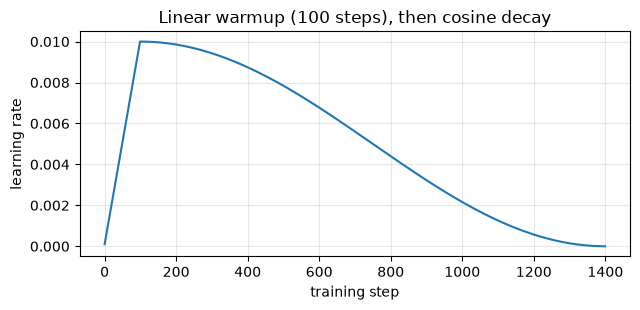

In [8]:
steps = np.arange(1400)
plt.figure(figsize=(6.5, 3.2))
plt.plot(steps, [lr_at(s, 1e-2, 1400, 100) for s in steps])
plt.xlabel("training step"); plt.ylabel("learning rate"); plt.title("Linear warmup (100 steps), then cosine decay")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 6.1 Choosing the learning rate on validation

The peak learning rate is the most important setting to get right, so we choose it with a short experiment: train for 200 steps at three learning rates, with a constant learning rate and no warmup, and compare the **validation** loss. We never use the validation data to compute gradients, and we use the same random batches for every run.

In [9]:
sweep = {}
for lr in [1e-3, 3e-3, 1e-2]:
    m, _ = train(lr, steps=200, warmup=0, schedule=False)
    sweep[lr] = val_loss(m)
    print(f"peak learning rate {lr:<6}: validation loss after 200 steps {sweep[lr]:.3f}")
best_lr = min(sweep, key=sweep.get)
print("chosen on validation:", best_lr)

peak learning rate 0.001 : validation loss after 200 steps 2.489


peak learning rate 0.003 : validation loss after 200 steps 2.330


peak learning rate 0.01  : validation loss after 200 steps 2.190
chosen on validation: 0.01


After 200 steps, a learning rate of 0.001 reaches a validation loss of 2.489, 0.003 reaches 2.330 and 0.01 reaches 2.190. The highest learning rate wins, so we choose 0.01.

A caution about short sweeps: they favour higher learning rates, because a larger step size makes faster progress early on, even if it might cause trouble later. That is one reason we pair the chosen rate with warmup and decay, and why we check the full run's curves rather than trusting the sweep blindly.

> **Common mistake:** choosing settings by looking at the test set, or at the training loss. Training loss rewards memorisation; the test set must stay untouched until the very end. Choose on validation.

## 7. Training on Tiny Shakespeare and Reading the Loss Curves

Now the main run: 1,400 steps with a peak learning rate of 0.01, 100 warmup steps, cosine decay, AdamW and clipping at 1.0. Every 100 steps, we measure the validation loss. We also keep a copy of the untrained model for comparison.

In [10]:
STEPS, WARMUP = 1400, 100
torch.manual_seed(0); untrained = GPT(V)                 # a copy of the starting point, for comparisons later
model, log = train(best_lr, STEPS, warmup=WARMUP, eval_every=100)
print("validation loss every 100 steps:", [round(float(v), 3) for _, v in log["val"]])
print(f"final validation loss: {log['val'][-1][1]:.3f}")
print(f"average training loss over the last 100 steps: {np.mean(log['train'][-100:]):.3f}")

validation loss every 100 steps: [2.487, 2.222, 2.111, 2.006, 1.95, 1.906, 1.864, 1.845, 1.805, 1.788, 1.765, 1.752, 1.744, 1.742]
final validation loss: 1.742
average training loss over the last 100 steps: 1.547


The validation loss falls steadily, from 2.487 after 100 steps to 1.742 at the end. It is still creeping down at the end, but slowly: the last three measurements are 1.752, 1.744 and 1.742, as the cosine schedule brings the learning rate down to zero. The average training loss over the last 100 steps is 1.547. Let's look at the curves, together with the gradient norms.

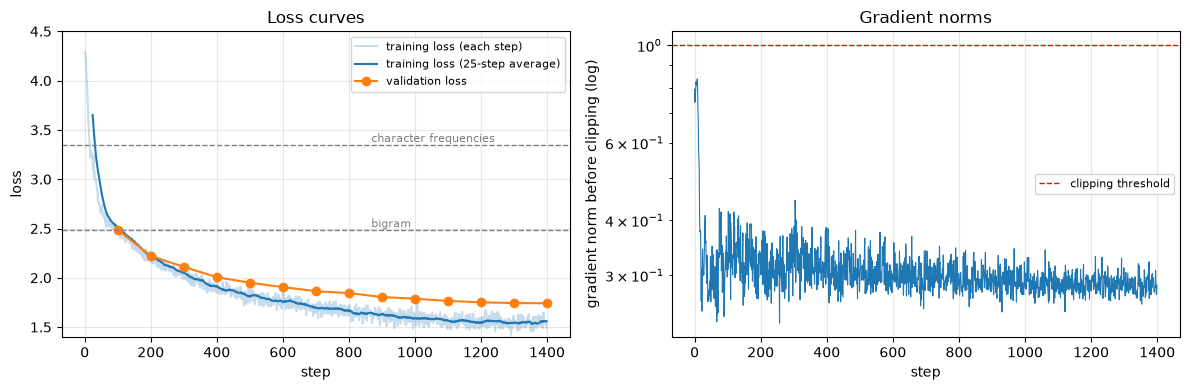

steps where clipping was active (norm above 1.0): 0 of 1400
largest gradient norm: 0.84 (at step 8) | median: 0.30


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sm = np.convolve(log["train"], np.ones(25) / 25, mode="valid")
axes[0].plot(log["train"], alpha=0.25, color="tab:blue", label="training loss (each step)")
axes[0].plot(np.arange(24, STEPS), sm, color="tab:blue", label="training loss (25-step average)")
axes[0].plot(*zip(*log["val"]), "o-", color="tab:orange", label="validation loss")
for v_, name in [(val_unigram, "character frequencies"), (val_bigram, "bigram")]:
    axes[0].axhline(v_, ls="--", lw=1, color="grey"); axes[0].text(STEPS * 0.62, v_ + 0.03, name, fontsize=8, color="grey")
axes[0].set_xlabel("step"); axes[0].set_ylabel("loss"); axes[0].set_ylim(1.4, 4.5); axes[0].legend(fontsize=8)
axes[0].set_title("Loss curves"); axes[0].grid(alpha=0.3)
axes[1].plot(log["grad_norm"], lw=0.8); axes[1].axhline(1.0, color="red", ls="--", lw=1, label="clipping threshold")
axes[1].set_yscale("log"); axes[1].set_xlabel("step"); axes[1].set_ylabel("gradient norm before clipping (log)")
axes[1].set_title("Gradient norms"); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
gn = np.array(log["grad_norm"])
print(f"steps where clipping was active (norm above 1.0): {(gn > 1.0).sum()} of {STEPS}")
print(f"largest gradient norm: {gn.max():.2f} (at step {gn.argmax()}) | median: {np.median(gn):.2f}")

**Reading the loss curves (left).** Start with the baselines. The model passes the character-frequency baseline (3.347) almost immediately, and the bigram baseline (2.482) at about step 100, where its validation loss is 2.487. From there on it is using more than one character of context. It ends at 1.742, far below the bigram's 2.482.

Notice the growing gap between training loss (1.547 at the end) and validation loss (1.742). The model does somewhat better on the plays it trained on than on the held-out ones, but both curves are still falling together, with no sign of the validation loss turning upwards. This is a healthy **generalisation gap**, not yet overfitting: in Module 3's terms, "train ↓, validation ↓".

**Reading the gradient norms (right).** The gradient norm starts high in the first few steps, peaking at 0.84 at step 8, then settles around a median of 0.30. It never reaches the clipping threshold of 1.0: clipping was active on 0 of 1,400 steps. In this run, with pre-norm blocks and warmup, clipping turned out to be unnecessary. That is typical of a healthy run: clipping is **insurance**, which only matters when a bad batch or an unstable setup produces a spike like the 117.6 in Note 6.4's collapsed post-norm run. It costs almost nothing to keep.

### 7.1 What did the model learn?

Let's compare the untrained and trained models' predictions after a few prompts.

In [12]:
@torch.no_grad()
def next_distribution(model, prompt):
    model.eval()
    logits, _ = model(torch.tensor([encode(prompt[-CONTEXT:])]))
    return logits[0, -1]                                                  # scores for the next character

prompts = ["First Citiz", "KING RICH", "What light through yonder windo", "my good lor"]
for prompt in prompts:
    for name, m in [("untrained", untrained), ("trained", model)]:
        p = F.softmax(next_distribution(m, prompt), dim=-1)
        top = p.topk(3)
        print(f"{name:<9} after {prompt!r:<34} top 3 =",
              [(repr(itos[i.item()]), round(v.item(), 3)) for v, i in zip(top.values, top.indices)])

untrained after 'First Citiz'                      top 3 = [("'W'", 0.042), ("'P'", 0.035), ("'\\n'", 0.031)]
trained   after 'First Citiz'                      top 3 = [("'e'", 0.966), ("'i'", 0.013), ("'o'", 0.006)]
untrained after 'KING RICH'                        top 3 = [("'t'", 0.05), ("'n'", 0.041), ("'S'", 0.037)]
trained   after 'KING RICH'                        top 3 = [("'A'", 0.986), ("'M'", 0.003), ("'E'", 0.003)]
untrained after 'What light through yonder windo'  top 3 = [("'u'", 0.042), ("'g'", 0.042), ("'G'", 0.035)]
trained   after 'What light through yonder windo'  top 3 = [("'m'", 0.396), ("'n'", 0.353), ("'w'", 0.069)]
untrained after 'my good lor'                      top 3 = [("'t'", 0.042), ("'u'", 0.038), ("'h'", 0.035)]
trained   after 'my good lor'                      top 3 = [("'d'", 0.993), ("'s'", 0.001), ("'y'", 0.001)]


The untrained model's best guesses are random, around 0.04 to 0.05 each. The trained model is confident and usually right:

- After "First Citiz" it predicts `'e'` with probability 0.966: it knows the speaker name "First Citizen".
- After "KING RICH" it predicts `'A'` with 0.986: it knows "KING RICHARD", written in capitals.
- After "my good lor" it predicts `'d'` with 0.993.

But not always. After "What light through yonder windo" its top guesses are `'m'` (0.396) and `'n'` (0.353), and the correct `'w'` gets only 0.069. "Window" is rare in this text, and a small model trained for a couple of minutes has not learned it; "windom" and "window" might be equally plausible to it as spellings. Its knowledge is real but patchy.

### 7.2 How much context does the model use?

The model sees up to 64 characters, but how much does it actually benefit from them? We can measure the validation loss separately at each position in the window: at position 0 the model has seen only one character, at position 63 it has seen 64.

position  0 (sees  1 characters): trained validation loss 2.424
position  1 (sees  2 characters): trained validation loss 2.196
position  2 (sees  3 characters): trained validation loss 1.952
position  4 (sees  5 characters): trained validation loss 1.794
position  8 (sees  9 characters): trained validation loss 1.712
position 16 (sees 17 characters): trained validation loss 1.663
position 32 (sees 33 characters): trained validation loss 1.770
position 63 (sees 64 characters): trained validation loss 1.748


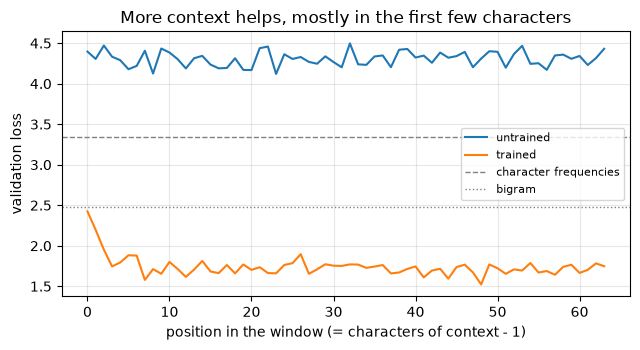

In [13]:
@torch.no_grad()
def loss_by_position(m):
    m.eval()
    per_pos = torch.zeros(CONTEXT)
    for xv, yv in VAL_BATCHES:
        logits, _ = m(xv)
        per_pos += F.cross_entropy(logits.transpose(1, 2), yv, reduction="none").mean(0)   # (64,) one loss per position
    return (per_pos / len(VAL_BATCHES)).numpy()

lp_trained, lp_untrained = loss_by_position(model), loss_by_position(untrained)
for pos in [0, 1, 2, 4, 8, 16, 32, 63]:
    print(f"position {pos:>2} (sees {pos + 1:>2} characters): trained validation loss {lp_trained[pos]:.3f}")
plt.figure(figsize=(6.5, 3.6))
plt.plot(lp_untrained, label="untrained"); plt.plot(lp_trained, label="trained")
plt.axhline(val_unigram, color="grey", ls="--", lw=1, label="character frequencies")
plt.axhline(val_bigram, color="grey", ls=":", lw=1, label="bigram")
plt.xlabel("position in the window (= characters of context - 1)"); plt.ylabel("validation loss")
plt.title("More context helps, mostly in the first few characters"); plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

At position 0, with just one character to go on, the validation loss is 2.424, close to the bigram model's 2.482. That makes sense: with one character of context, the Transformer can do little more than a bigram model. The loss falls quickly as context grows: 2.196 with 2 characters, 1.952 with 3, 1.794 with 5 and 1.712 with 9. After that, the curve flattens out at roughly 1.7, with some noise from position to position: 1.663 at position 16, 1.770 at 32 and 1.748 at 63.

So our small model uses roughly the last ten characters well, enough for spelling, word endings and common short phrases, but it gains little from context further back. Exploiting long-range context requires more capacity and more training; that is a large part of what makes big language models big.

### 7.3 Inside the trained attention

In Note 6.3 we built, by hand, a head that attends to the previous token. Did training produce anything similar? Here are the attention weights of the four heads in the first block for the line "KING RICHARD:\nThe king is dead", with numbers summarising, for each head, how much weight goes to each distance back.

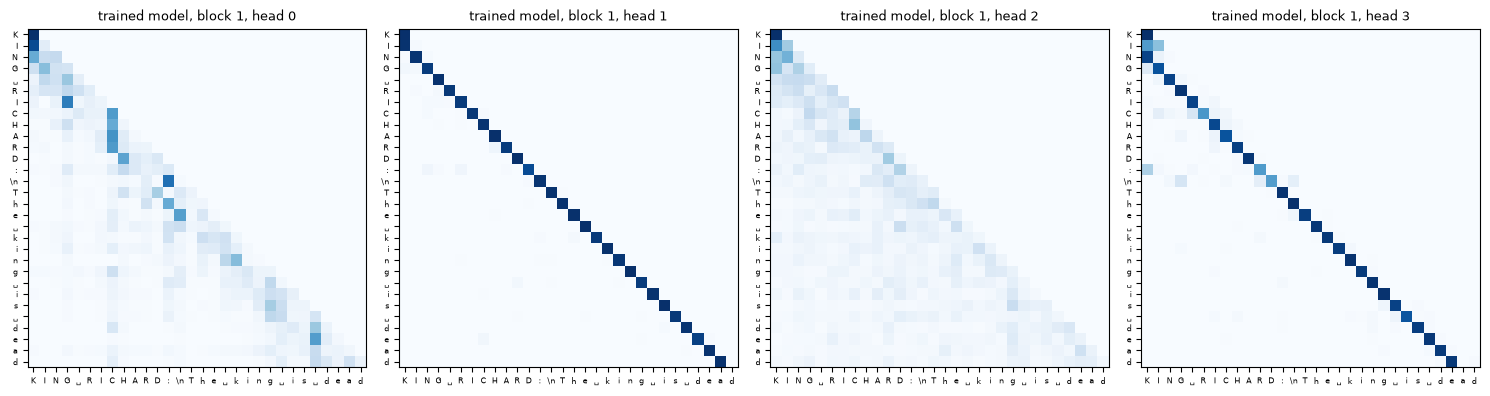

average attention weight at each distance back (0 = itself, 1 = previous character, ...):
  head 0: 0 back: 0.12  1 back: 0.20  2 back: 0.18  3 back: 0.24
  head 1: 0 back: 0.04  1 back: 0.97  2 back: 0.00  3 back: 0.00
  head 2: 0 back: 0.13  1 back: 0.20  2 back: 0.10  3 back: 0.12
  head 3: 0 back: 0.06  1 back: 0.03  2 back: 0.91  3 back: 0.03


In [14]:
@torch.no_grad()
def attention_weights(model, text_, layer):
    ids = torch.tensor([encode(text_)])
    x = model.tok_emb(ids) + model.pos_emb(torch.arange(ids.shape[1]))
    for i, b in enumerate(model.blocks):
        if i == layer:
            h = b.ln1(x); B, T, D = h.shape; H = b.attn.n_heads
            q, k, _ = b.attn.qkv(h).split(D, dim=2)
            q, k = [t.view(B, T, H, D // H).transpose(1, 2) for t in (q, k)]
            s = q @ k.transpose(-2, -1) / math.sqrt(D // H)
            return torch.softmax(s.masked_fill(~torch.tril(torch.ones(T, T, dtype=torch.bool)), float("-inf")), -1)[0]
        x = b(x)

line = "KING RICHARD:\nThe king is dead"
model.eval()
w0 = attention_weights(model, line, layer=0)
labels = [repr(c)[1:-1] if c != " " else "␣" for c in line]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.4))
for h, ax in enumerate(axes):
    ax.imshow(w0[h], cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(line)), labels, fontsize=6); ax.set_yticks(range(len(line)), labels, fontsize=6)
    ax.set_title(f"trained model, block 1, head {h}", fontsize=9)
plt.tight_layout(); plt.show()
T_ = len(line)
print("average attention weight at each distance back (0 = itself, 1 = previous character, ...):")
for h in range(4):
    prof = [np.mean([w0[h, i, i - d].item() for i in range(d, T_)]) for d in range(4)]
    print(f"  head {h}: " + "  ".join(f"{d} back: {v:.2f}" for d, v in enumerate(prof)))

Two heads have learned sharp positional rules entirely on their own:

- **Head 1** puts an average weight of 0.97 on the **previous character**: it is the "previous token" head we designed by hand in Note 6.3, discovered by training.
- **Head 3** puts 0.91 on the character **two** positions back.

Together, they let the next block see the last three characters directly. Heads 0 and 2 spread their attention more widely over the recent past (no more than 0.24 on any single distance in the first few), gathering broader context. Compare these sharp, purposeful patterns with the noisy weights of the untrained module in Note 6.3.

> **Common mistake:** reading too much into a single attention map. Attention shows where information is *gathered from*, not what is done with it, and later blocks may change everything. Here we backed the pictures with averages over a whole line; for real conclusions, measure over many inputs.

## 8. Autoregressive Inference

Now the second half: generation. A trained model gives us a probability distribution for the next character. To write text, we repeat four steps:

1. Run the model on the text so far (at most the last 64 characters, the context window).
2. Take the logits at the **last** position only: the model's scores for the next character.
3. **Choose** a character from them. Section 9 is about how.
4. Append it to the text, and go back to step 1.

This is called **autoregressive** generation: each new token is predicted from the model's own previous outputs. Here is the full function, with the choice step written to support all the strategies of Section 9, followed by 300 characters generated after the prompt "ROMEO:" by sampling from the model's distribution as it is.

In [15]:
@torch.no_grad()
def generate(model, prompt, n_new, temperature=1.0, top_k=None, top_p=None, seed=0):
    model.eval()
    g = torch.Generator().manual_seed(seed)
    ids = encode(prompt)
    for _ in range(n_new):
        logits = next_distribution(model, decode(ids))          # 1. run the model on the text so far
        if temperature == 0:                                     # greedy: always the single most likely token
            ids.append(int(logits.argmax())); continue
        logits = logits / temperature                            # 2. sharpen (<1) or flatten (>1)
        if top_k is not None:                                    # 3a. keep only the k most likely tokens
            kth = logits.topk(top_k).values[-1]
            logits = logits.masked_fill(logits < kth, float("-inf"))
        if top_p is not None:                                    # 3b. keep the smallest set with total probability >= p
            sorted_logits, order = logits.sort(descending=True)
            cum = F.softmax(sorted_logits, -1).cumsum(-1)
            drop = cum - F.softmax(sorted_logits, -1) >= top_p
            logits[order[drop]] = float("-inf")
        probs = F.softmax(logits, dim=-1)
        ids.append(int(torch.multinomial(probs, 1, generator=g)))   # 4. draw the next token
    return decode(ids)

print(generate(model, "ROMEO:\n", 300, temperature=1.0, seed=0))

ROMEO:
Thy for this when? I would nextand, in I to thee,
Is upon his thee rechest of bleepelies.
To him; that's your wake excheeksiard;
Her none have too we woot to a man is hither.

DORK:

BUCKINGHRMOP.

QUEEN MERSET:

KINGHAM:
Senatisarful too queen to this suild.

JULIET:
Farink'S yound, Englace that ha


Compare this with the random characters of the untrained model in Note 6.5. The trained model has learned the **form** of a play: speaker names in capitals followed by a colon and a line break ("JULIET:", "QUEEN MERSET:", "KINGHAM:"), lines of verse that start with capitals, punctuation in sensible places, and many real words ("I would", "to thee", "that's your", "a man is hither"). It has not learned **meaning**: the sentences do not make sense, and it invents words ("bleepelies", "excheeksiard") and names ("BUCKINGHRMOP"). For a 162,561-parameter model trained for a couple of minutes on one CPU core, reading one character at a time, that is about what we should expect.

## 9. Greedy Decoding and Sampling

At step 3 of the generation loop, the model gives us a probability distribution, and we must turn it into a single choice. This choice, called the **decoding strategy**, has a big effect on the text.

- **Greedy decoding** always picks the single most likely token. It is deterministic: the same prompt always gives the same text.
- **Sampling** draws the next token at random according to the model's probabilities, so a token with probability 0.3 is chosen about 30% of the time.

Sampling is usually modified in one of three ways:

- **Temperature.** Divide the logits by a number T before softmax. T below 1 makes the distribution sharper (more confident); T above 1 makes it flatter (more adventurous); T = 1 leaves it unchanged; and T approaching 0 becomes greedy.
- **Top-k.** Keep only the k most likely tokens and set the rest to zero probability before sampling.
- **Top-p** (nucleus sampling). Keep the smallest set of most likely tokens whose probabilities add up to at least p, and drop the rest. Unlike top-k, the number of candidates adapts to how confident the model is.

Let's see temperature's effect on one real distribution: the model's prediction for the character after "...What light through yonder ".

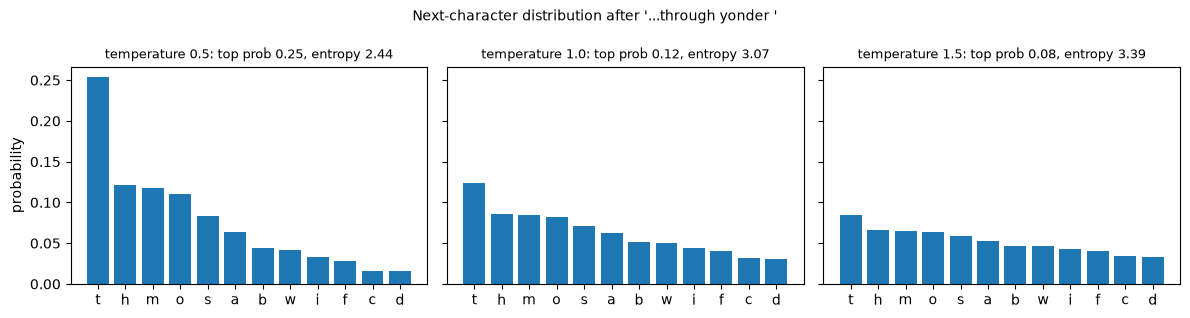

temperature 0.5: top probability 0.25 for 't' | entropy 2.44
temperature 1.0: top probability 0.12 for 't' | entropy 3.07
temperature 1.5: top probability 0.08 for 't' | entropy 3.39
candidates kept by top-p 0.9 here: 18 | by top-k 5: 5


In [16]:
logits = next_distribution(model, "ROMEO:\nWhat light through yonder ")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, t in zip(axes, [0.5, 1.0, 1.5]):
    p = F.softmax(logits / t, -1); top = p.topk(12)
    ax.bar([repr(itos[i.item()])[1:-1] or "␣" for i in top.indices], top.values.numpy())
    ent = -(p * p.log()).sum().item()
    ax.set_title(f"temperature {t}: top prob {top.values[0]:.2f}, entropy {ent:.2f}", fontsize=9)
axes[0].set_ylabel("probability"); plt.suptitle("Next-character distribution after '...through yonder '", fontsize=10)
plt.tight_layout(); plt.show()
for t in [0.5, 1.0, 1.5]:
    p_t = F.softmax(logits / t, -1)
    print(f"temperature {t}: top probability {p_t.max():.2f} for {repr(itos[p_t.argmax().item()])} | entropy {-(p_t * p_t.log()).sum():.2f}")
p = F.softmax(logits, -1); sp = p.sort(descending=True).values
print("candidates kept by top-p 0.9 here:", int(((sp.cumsum(0) - sp) < 0.9).sum()), "| by top-k 5: 5")

At temperature 1.0 the most likely next character is `'t'` (as in "the" or "thy") with probability 0.12, with an entropy of 3.07. At temperature 0.5 the same distribution becomes much sharper, with `'t'` at 0.25 and the entropy down to 2.44. At 1.5 it flattens to 0.08 and 3.39. Temperature never changes the *order* of the candidates, only how strongly the model prefers the top ones. Here, top-p with p = 0.9 keeps 18 candidates, while top-k with k = 5 would keep exactly 5.

Now let's measure what each strategy does to the generated text. For each strategy we generate 300 characters after "ROMEO:", three times with different random seeds, and measure two things:

- **Real words:** the share of generated words that appear somewhere in the training text, a rough measure of correctness.
- **Distinct 8-character pieces:** the share of all 8-character stretches of the output that are different from each other, a measure of variety. Text that repeats itself scores low.

In [17]:
train_words = set(re.findall(r"[A-Za-z']+", decode(train_ids.tolist())))
def quality(sample, prompt_len):
    words = re.findall(r"[A-Za-z']+", sample[prompt_len:])
    real = np.mean([w in train_words for w in words]) if words else 0.0
    grams = [sample[i:i + 8] for i in range(prompt_len, len(sample) - 8)]
    distinct = len(set(grams)) / max(1, len(grams))
    return real, distinct

settings = [("greedy (temperature 0)", dict(temperature=0)),
            ("temperature 0.5", dict(temperature=0.5)),
            ("temperature 1.0", dict(temperature=1.0)),
            ("temperature 1.5", dict(temperature=1.5)),
            ("top-k, k = 5", dict(temperature=1.0, top_k=5)),
            ("top-p, p = 0.9", dict(temperature=1.0, top_p=0.9))]
P0 = "ROMEO:\n"
samples = {}
print(f"{'decoding':<24} {'real words':>10} {'distinct 8-char pieces':>23}")
for name, kw in settings:
    real, dist = [], []
    for seed in range(3):
        s = generate(model, P0, 300, seed=seed, **kw)
        r, d = quality(s, len(P0)); real.append(r); dist.append(d)
        if seed == 0: samples[name] = s
    print(f"{name:<24} {np.mean(real):>10.3f} {np.mean(dist):>23.3f}")

decoding                 real words  distinct 8-char pieces


greedy (temperature 0)        0.984                   0.188


temperature 0.5               0.919                   0.992


temperature 1.0               0.801                   0.997


temperature 1.5               0.450                   1.000


top-k, k = 5                  0.869                   1.000


top-p, p = 0.9                0.830                   0.997


The trade-off is very clear:

| Decoding | Real words | Distinct 8-character pieces |
|---|---|---|
| Greedy | 0.984 | 0.188 |
| Temperature 0.5 | 0.919 | 0.992 |
| Temperature 1.0 | 0.801 | 0.997 |
| Temperature 1.5 | 0.450 | 1.000 |
| Top-k, k = 5 | 0.869 | 1.000 |
| Top-p, p = 0.9 | 0.830 | 0.997 |

**Greedy** decoding uses almost only real words (0.984), but only 0.188 of its 8-character pieces are distinct: it repeats itself. **Raising the temperature** steadily trades correctness for variety: at 1.5, fewer than half the words are real (0.450). **Top-k and top-p** improve on plain sampling at temperature 1.0 (0.869 and 0.830 real words, against 0.801) without losing variety, because they cut off the long tail of unlikely characters, where most invented words come from. Here are some of the samples behind those numbers:

In [18]:
for name in ["greedy (temperature 0)", "temperature 0.5", "temperature 1.5", "top-p, p = 0.9"]:
    print(f"===== {name} =====")
    print(samples[name][:230]); print()

===== greedy (temperature 0) =====
ROMEO:
I am the shall the shall be some to the conter
To the stand the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the

===== temperature 0.5 =====
ROMEO:
There have the self made thee hand,
And genemently of the countrest may the poor
And serve the contents of or way we with that thou we never thee.

LADY ANNE:
I'll is he did the contring.

First Marcius, I will not is the e

===== temperature 1.5 =====
ROMEO:
thyre his khaxps:
LeWToHat nexhand, in IgAlsternay
oful you foth here hath Doigs
Apeliess. I havest at's your wake excheeksiard;
Her ne-days thysorrely you for 'falion?

LEONTESS Lantsmuzen:
Renjure a mother plain-will moon

===== top-p, p = 0.9 =====
ROMEO:
Thou must therest triboural expace,
And get the recome of his therefess the hight.

First Gentleman:
Who speak a pervace trucker, to not my father well.

RIVERS:
He seek, the he c

The greedy output falls into a loop almost immediately: "the shall the shall the shall..." over and over. Once the model has produced "the shall", the most likely continuation leads straight back to it, and greedy decoding has no way to escape. Temperature 0.5 reads most like English, with plausible phrases such as "serve the contents". Temperature 1.5 dissolves into invented words and stray capitals ("LeWToHat nexhand"). Top-p keeps the variety while producing a more convincing play layout.

There is no single best setting: it depends on the use. For a factual answer you want something close to greedy; for creative writing, more variety. Chat assistants typically sample with a moderate temperature together with top-p.

> **Common mistake:** concluding that a model is "broken" because greedy decoding produces endless repetition. Repetition loops are a known property of greedy decoding, not necessarily of the model. Try sampling with temperature, top-k or top-p before drawing conclusions.

> **Key terms**
> - **Autoregressive generation:** producing a sequence one token at a time, each predicted from the tokens generated so far.
> - **Decoding strategy:** the rule for choosing a token from the model's distribution.
> - **Greedy decoding:** always choosing the most likely token.
> - **Temperature:** dividing logits by T before softmax; T < 1 sharpens, T > 1 flattens.
> - **Top-k / top-p sampling:** sampling only from the k most likely tokens / from the smallest set covering probability p.

> **Check yourself 2.** At temperature 0.5, the model's top probability after "...through yonder " rose from 0.12 to 0.25. What would you expect at temperature 0.1?

## 10. Training vs. Inference

Training and generation use the same model, but they differ in important ways:

| | Training | Inference (generation) |
|---|---|---|
| Input | Real text windows | The prompt plus the model's own output |
| Positions predicted | All of them at once (teacher forcing) | One new token per forward pass |
| Gradients | Computed (`loss.backward()`) | Not needed (`torch.no_grad()`) |
| Model mode | `model.train()` | `model.eval()` |
| Speed bottleneck | Total compute per batch | One forward pass per generated token |

Two of these differences show up directly in code:

In [19]:
model.train(); print("model.training after model.train():", model.training)
model.eval();  print("model.training after model.eval(): ", model.training)
with torch.no_grad():
    _, l = model(*VAL_BATCHES[0])
print("gradients tracked inside torch.no_grad()?", l.requires_grad)
print("forward passes needed to generate 300 characters:", 300)

model.training after model.train(): True
model.training after model.eval():  False
gradients tracked inside torch.no_grad()? False
forward passes needed to generate 300 characters: 300


`model.train()` and `model.eval()` set the model's `training` flag (`True` and `False`). Our model has no dropout or batch normalisation, so the flag changes nothing here, but in models that have them it changes their behaviour, so the correct mode is a habit worth keeping (Module 2). Inside `torch.no_grad()`, the loss has `requires_grad` equal to `False`: PyTorch does not store anything for backpropagation, which saves memory and time during generation.

The last line points to the main cost of generation: 300 new characters need 300 separate forward passes, one after another. Training processes many positions in parallel, but generation is inherently sequential. Production systems speed this up with a **KV cache**, which stores the keys and values already computed for earlier tokens so that each new step only has to process the newest token. You will meet it again in Module 7.

The other important difference is **exposure bias**: during training the model always saw real text, but during generation it sees its own output, mistakes included. One invented word, such as "BUCKINGHRMOP", becomes part of the context for everything that follows, and the model was never trained to recover from its own errors. Sampling strategies that avoid unlikely tokens reduce this problem; they do not remove it.

> **Key terms**
> - **Inference:** using a trained model to make predictions, without updating its weights.
> - **KV cache:** stored keys and values of earlier tokens, reused so each generation step only processes the new token.
> - **Exposure bias:** the mismatch between training on real text and generating from the model's own outputs.

> **Check yourself 3.** Why can training process all 64 positions of a window in one forward pass, while generation needs one forward pass per new character?

## Putting It All Together

A language model learns by **next-token prediction**. Each training window `x` comes with a target `y` shifted one position left, and with **teacher forcing** and the causal mask, one forward pass makes a prediction at every position: 2,048 per batch. The loss is **cross-entropy**, −log(probability of the true next character), averaged over all positions, and we read it against baselines: 4.174 (uniform), 3.347 (character frequencies) and 2.482 (bigram).

We trained our 162,561-parameter model with AdamW, a 100-step warmup, cosine decay and gradient clipping, choosing the peak learning rate of 0.01 on validation (2.190 after 200 steps, against 2.330 and 2.489). After 1,400 steps it reached a validation loss of 1.742, with a healthy gap to the training loss (1.547). Clipping never activated: insurance, not a necessity, in a stable run. The model uses about the last ten characters well. One of its attention heads attends to the previous character with weight 0.97 and another to the character two back with 0.91, the kind of head we designed by hand in Note 6.3.

To generate, the model runs **autoregressively**: predict, choose, append, repeat. The **decoding strategy** controls the result. Greedy decoding used real words (0.984) but looped ("the shall the shall..."); higher temperatures added variety at the cost of real words (0.450 at temperature 1.5); top-k and top-p cut the unlikely tail and kept both reasonably high. The model learned the form of a play, but not its meaning. Generation is sequential and suffers from **exposure bias**, because the model must build on its own mistakes.

That completes Module 6: you have built a Transformer from its parts, trained it, and generated text with it. In Module 7 you will use Transformers that others have pretrained at enormous scale, and in Module 8 you will adapt them to your own tasks.

> 🖼 *IMAGE 6.6.2 — Module 6 in One Picture.* A circular cycle diagram on a white background with five stations connected by arrows. Station 1 "Text → tokens → windows" (a page icon turning into tiles and a bracket of 64). Station 2 "Transformer" (a small stack of three blocks with attention lines). Station 3 "Loss" (a bar chart with the true next character highlighted, labelled "−log p(correct)"). Station 4 "Update" (a downhill arrow on a curve, labelled "AdamW, warmup, cosine, clipping"). From Station 2 a second branch leaves the cycle to Station 5 "Generate" (a chain of characters growing one tile at a time, with a small dial labelled "temperature / top-k / top-p"). In the centre: "next-token prediction". Takeaway: the same model learns by predicting the next token on real text, and writes by predicting the next token on its own output.

## Summary

- Language models learn by **next-token prediction**, a self-supervised task: targets are the input shifted one position left.
- The loss is **cross-entropy**, −log(probability of the correct token), averaged over all positions. Read it against baselines (uniform, unigram, bigram).
- **Teacher forcing** feeds the true previous tokens during training, which makes all positions computable in parallel.
- Stable training uses **AdamW**, **warmup**, a **cosine** learning-rate schedule and **gradient clipping**; choose the learning rate on validation.
- Our model reached a validation loss of 1.742 (bigram 2.482), used about the last ten characters effectively, and learned "previous character" and "two characters back" attention heads.
- Generation is **autoregressive**: predict, choose, append, repeat.
- **Greedy decoding** is accurate but repetitive; **temperature** trades correctness for variety; **top-k** and **top-p** remove unlikely tokens and balance the two.
- Inference needs no gradients, uses `model.eval()`, runs one forward pass per new token (sped up by a **KV cache**), and suffers from **exposure bias**.

## Glossary

| Term | Meaning |
|---|---|
| Next-token prediction | Predicting each token from the tokens before it. |
| Self-supervised learning | Learning from targets derived from the data itself. |
| Label shifting | Making targets by shifting the input one position left. |
| Cross-entropy loss | −log(probability of the correct token), averaged over positions. |
| Unigram / bigram baseline | A predictor using no context / only the previous token. |
| Teacher forcing | Training with the true previous tokens as input, not the model's own predictions. |
| AdamW | Adam with decoupled weight decay; the standard Transformer optimizer. |
| Weight decay | A small pull of weights towards zero, for regularisation. |
| Warmup | Increasing the learning rate gradually at the start of training. |
| Cosine decay | Lowering the learning rate along half a cosine wave. |
| Gradient clipping | Rescaling gradients whose norm exceeds a threshold. |
| Generalisation gap | The difference between training and validation loss. |
| Autoregressive generation | Producing tokens one at a time, each from the previous outputs. |
| Decoding strategy | The rule for choosing a token from the predicted distribution. |
| Greedy decoding | Always choosing the most likely token. |
| Temperature | A divisor of the logits that sharpens (< 1) or flattens (> 1) the distribution. |
| Top-k / top-p sampling | Sampling from the k most likely tokens / from the smallest set with total probability ≥ p. |
| KV cache | Stored keys and values of earlier tokens, reused during generation. |
| Exposure bias | The mismatch between training on real text and generating from the model's own output. |

## Answers to Check Yourself

**1.** −log(0.25) = log(4) ≈ 1.386.

**2.** Dividing the logits by 0.1 multiplies the differences between them by 10, so the distribution becomes extremely sharp: almost all the probability would go to `'t'`, and the result would be very close to greedy decoding.

**3.** During training, the input at every position is real text that is known in advance, so every position's prediction can be computed at once (with the causal mask keeping each one honest). During generation, the input at the next position is the character the model is about to choose, which does not exist until the current step has finished, so each step must wait for the previous one.